### basic a chatbot with langgraph(graph apl)


In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

In [3]:
graph_builder

In [4]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [5]:
import os
from dotenv import load_dotenv

load_dotenv()

print("GROQ KEY:", bool(os.getenv("GROQ_API_KEY")))

GROQ KEY: True


In [6]:
from dotenv import load_dotenv
load_dotenv()

from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b"
)

response = llm.invoke("Say hello")

print(response.content)

Hello! 👋 How can I help you today?


In [7]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

In [8]:
from langgraph.graph import StateGraph, START, END

In [9]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [10]:
graph_builder = StateGraph(State)

graph_builder.add_node("llmchatbot", chatbot)

graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

graph = graph_builder.compile()

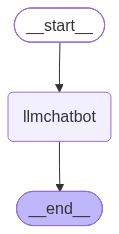

In [11]:
# VISUALIZE THE GRAPH
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [12]:
graph.invoke({"messages": ["hi"]})

{'messages': [HumanMessage(content='hi', additional_kwargs={}, response_metadata={}, id='91ef64f8-3bfa-4c18-8033-44c0ca792096'),
  AIMessage(content='Hello! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond to user greeting "hi". It\'s a general chat. The instruction says we should respond as ChatGPT. So a friendly reply.'}, response_metadata={'token_usage': {'completion_tokens': 51, 'prompt_tokens': 72, 'total_tokens': 123, 'completion_time': 0.069902208, 'completion_tokens_details': {'reasoning_tokens': 31}, 'prompt_time': 0.004044492, 'prompt_tokens_details': None, 'queue_time': 0.307875136, 'total_time': 0.0739467}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e594c51153', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0b827-b459-7900-a8bb-471c221f2d01-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 51, 'total_tok

In [13]:
response = graph.invoke({"messages": ["hi"]})

In [14]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [15]:
for event in graph.stream({"messages": ["hi", "how are you"]}):
    print(event)

{'llmchatbot': {'messages': [AIMessage(content="Hello! I'm doing great—thanks for asking. How can I help you today?", additional_kwargs={'reasoning_content': "We need to respond to user greeting. It's a simple conversation. Just respond politely."}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 79, 'total_tokens': 123, 'completion_time': 0.093660907, 'completion_tokens_details': {'reasoning_tokens': 18}, 'prompt_time': 0.00550099, 'prompt_tokens_details': None, 'queue_time': 0.222652758, 'total_time': 0.099161897}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e23fc997ca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0b827-b825-71f1-b614-a2ce30d9c61c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 79, 'output_tokens': 44, 'total_tokens': 123, 'output_token_details': {'reasoning': 18}})]}}


In [16]:
response = graph.invoke({
    "messages": ["Hello"]
})

print("Chatbot:", response["messages"][-1].content)

Chatbot: Hello! 👋 How can I help you today?


In [17]:
response = graph.invoke({
    "messages": ["Hello, how are you?"]
})

print("Chatbot:", response["messages"][-1].content)

Chatbot: Hello! I'm doing great—thanks for asking. How can I help you today?


In [18]:
while True:
    try:
        user_input = input("You: ")

        # Stop chatbot
        if user_input.lower().strip() in ["q", "quit", "exit"]:
            print("Chatbot: Goodbye! 👋")
            break

        # Empty input handle
        if not user_input.strip():
            print("Chatbot: Please type something.")
            continue

        # Send message to LangGraph
        response = graph.invoke({
            "messages": [user_input]
        })

        # Print chatbot response
        print("Chatbot:", response["messages"][-1].content)

    except KeyboardInterrupt:
        print("\nChatbot: Stopped! 👋")
        break

Chatbot: Hello! 👋 How can I help you today?
Chatbot: Goodbye! 👋


### chatbot with tool

In [19]:
import os
from dotenv import load_dotenv

load_dotenv()

from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)

result = tool.invoke({
    "query": "What is LangGraph?"
})

print(result)


{'query': 'What is LangGraph?', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph', 'title': 'What is LangGraph?', 'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] Agent systems: LangGraph provides a framework for building agent-based systems, which can be used in applications such as robotics, autonomous vehicles or video games.\n\nLLM applications: By using LangGraph’s capabilities, developers can build more sophisticated AI models that learn and improve over time. Norwegian Cruise Line

In [20]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)

tool.invoke("What is LangGraph?")

{'query': 'What is LangGraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph?',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] Agent systems: LangGraph provides a framework for building agent-based systems, which can be used in applications such as robotics, autonomous vehicles or video games.\n\nLLM applications: By using LangGraph’s capabilities, developers can build more sophisticated AI models that learn and improve over time. Norwegian C

In [21]:
## Custom function

def multiply(a: int, b: int) -> int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [22]:
tools = [multiply]

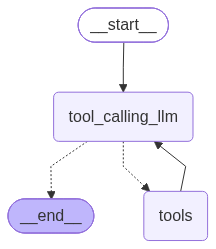

In [23]:
# ==============================
# LangGraph Tool-Calling Graph
# ==============================

from typing import Annotated
from typing_extensions import TypedDict

from IPython.display import Image, display

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition


# ------------------------------
# 1. Define State
# ------------------------------

class State(TypedDict):
    messages: Annotated[list, add_messages]


# ------------------------------
# 2. LLM Node
# ------------------------------

def tool_calling_llm(state: State):
    return {
        "messages": [
            llm_with_tool.invoke(state["messages"])
        ]
    }


# ------------------------------
# 3. Create StateGraph
# ------------------------------

builder = StateGraph(State)


# ------------------------------
# 4. Add Nodes
# ------------------------------

builder.add_node(
    "tool_calling_llm",
    tool_calling_llm
)

builder.add_node(
    "tools",
    ToolNode(tools)
)


# ------------------------------
# 5. Add Edges
# ------------------------------

# START → LLM
builder.add_edge(
    START,
    "tool_calling_llm"
)


# LLM → Tool OR END
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)


# Tool → LLM
builder.add_edge(
    "tools",
    "tool_calling_llm"
)


# ------------------------------
# 6. Compile Graph
# ------------------------------

graph = builder.compile()


# ------------------------------
# 7. Display Graph
# ------------------------------

display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [24]:
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

In [25]:
llm_with_tool = llm.bind_tools(tools)

In [26]:
llm_with_tool


_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.4', 'langchain': '1.3.15'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001BF63475810>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001BF63476210>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'multiply', 'description': 'Multiply a and b', 'parameters': {'propertie

In [27]:
response=graph.invoke({"messages":"what is the recent ai news?"})

In [28]:
response['messages'][-1].content

'Here’s a quick snapshot of the most talked‑about AI developments and headlines from the past few weeks (up to\u202fSept\u202f2026):\n\n| Date | Event / Release | Key Take‑aways |\n|------|-----------------|----------------|\n| **Sept\u202f12\u202f2026** | **OpenAI launches GPT‑5** | • 10‑billion‑parameter model with multimodal (text, image, audio) capabilities.<br>• “Self‑correcting” prompts that reduce hallucinations by ~70\u202f%.<br>• API now supports “fine‑tuning on‑the‑fly” for niche domains. |\n| **Sept\u202f10\u202f2026** | **Google Gemini‑4.5** | • 5‑billion‑parameter model with advanced reasoning and “memory‑augmented” context.<br>• Integrated with Google Workspace, enabling real‑time document editing and code generation. |\n| **Sept\u202f8\u202f2026** | **Anthropic releases Claude\u202f3.5** | • 3‑billion‑parameter model with a new “Constitutional AI” safety layer that dynamically adapts to user intent.<br>• 30\u202f% faster inference on Anthropic’s own hardware. |\n| **Sept

In [29]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

what is the recent ai news?
================================== Ai Message ==================================

Here’s a quick snapshot of the most talked‑about AI developments and headlines from the past few weeks (up to Sept 2026):

| Date | Event / Release | Key Take‑aways |
|------|-----------------|----------------|
| **Sept 12 2026** | **OpenAI launches GPT‑5** | • 10‑billion‑parameter model with multimodal (text, image, audio) capabilities.<br>• “Self‑correcting” prompts that reduce hallucinations by ~70 %.<br>• API now supports “fine‑tuning on‑the‑fly” for niche domains. |
| **Sept 10 2026** | **Google Gemini‑4.5** | • 5‑billion‑parameter model with advanced reasoning and “memory‑augmented” context.<br>• Integrated with Google Workspace, enabling real‑time document editing and code generation. |
| **Sept 8 2026** | **Anthropic releases Claude 3.5** | • 3‑billion‑parameter model with a new “Constitut

In [30]:
response = graph.invoke({
    "messages": "give me the recent ai news and then multiply 5 by 10?"
})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

give me the recent ai news and then multiply 5 by 10?
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_e7d645e4-15f6-4dfa-ab85-a59a911ed764)
 Call ID: fc_e7d645e4-15f6-4dfa-ab85-a59a911ed764
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: multiply

50
================================== Ai Message ==================================

**Recent AI News (as of September 2026)**  

| Date | Headline | Key Take‑aways |
|------|----------|----------------|
| **2026‑09‑12** | **OpenAI releases GPT‑5** | GPT‑5 introduces “adaptive context windows” that can dynamically expand to 1 million tokens, enabling truly long‑form reasoning and real‑time collaboration with large datasets. The model also incorporates a new safety‑layer that reduces hallucinations by 70 % compared to GPT‑4. |
| **2026‑09‑

## React agent architecture


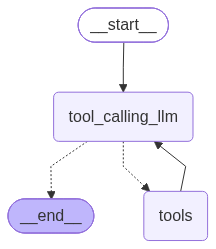

In [31]:
from langgraph.graph import StateGraph, START
from langgraph.prebuilt import ToolNode, tools_condition

# Node definition
def tool_calling_llm(state: State):
    return {
        "messages": [
            llm_with_tool.invoke(state["messages"])
        ]
    }

# Create graph
builder = StateGraph(State)

# Add nodes
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

# Add edge from START to LLM
builder.add_edge(START, "tool_calling_llm")

# Conditional edge
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# Return from tools to LLM
builder.add_edge("tools", "tool_calling_llm")

# Compile graph
graph = builder.compile()

# Display graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
response = graph.invoke({
    "messages": "give me the recent ai news and then multiply 5 by 10?"
})

for m in response["messages"]:
    m.pretty_print()
    

================================ Human Message =================================

give me the recent ai news and then multiply 5 by 10?
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_aaa601cb-1755-4973-9bb1-dbdee4b8fb76)
 Call ID: fc_aaa601cb-1755-4973-9bb1-dbdee4b8fb76
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: multiply

50
================================== Ai Message ==================================

**Recent AI News (as of September 2026)**  

| Date | Headline | Key Take‑aways |
|------|----------|----------------|
| **2026‑09‑12** | *OpenAI releases GPT‑5 with multimodal reasoning* | GPT‑5 can process text, images, audio, and video in a single prompt, achieving new state‑of‑the‑art performance on the MMLU benchmark (≈ 95 % accuracy). |
| **2026‑09‑10** | *Google DeepMind unveils AlphaHealth‑X* | A reinforcement‑learning‑driven system that designs p

## ADDING MEEMORY IN AGENT GRAPH


In [33]:
response = graph.invoke({
    "messages": "hello my name is dilshad?"
})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

hello my name is dilshad?
================================== Ai Message ==================================

Hello Dilshad! How can I help you today?


In [34]:
response = graph.invoke({
    "messages": "what is my name?"
})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is my name?
================================== Ai Message ==================================

I don’t have that information. If you tell me your name, I’ll remember it for our conversation!


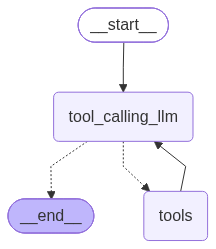

In [35]:
from langgraph.graph import StateGraph, START
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()
# Node definition
def tool_calling_llm(state: State):
    return {
        "messages": [
            llm_with_tool.invoke(state["messages"])
        ]
    }

# Create graph
builder = StateGraph(State)

# Add nodes
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

# Add edge from START to LLM
builder.add_edge(START, "tool_calling_llm")

# Conditional edge
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# Return from tools to LLM
builder.add_edge("tools", "tool_calling_llm")

# Compile graph
graph = builder.compile(checkpointer=memory)

# Display graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [36]:
config={"configurable": {"thread_id":"1"} }

graph.invoke({"messages": "hi my name is dilshad"}, config=config)


{'messages': [HumanMessage(content='hi my name is dilshad', additional_kwargs={}, response_metadata={}, id='2eb88767-ebdd-49b6-ae16-a448415b2da4'),
  AIMessage(content='Hello Dilshad! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hi my name is dilshad". We need to respond. Probably greet. No function call needed.'}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 134, 'total_tokens': 180, 'completion_time': 0.048061256, 'completion_tokens_details': {'reasoning_tokens': 25}, 'prompt_time': 0.007598371, 'prompt_tokens_details': None, 'queue_time': 0.345534637, 'total_time': 0.055659627}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_feb9b278f1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0b828-0341-7e53-8620-fd24538db9e1-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 134, 'output_tokens': 46, 'total_tokens': 180, 

In [37]:
response['messages'][-1].content

'I don’t have that information. If you tell me your name, I’ll remember it for our conversation!'

In [38]:
response = graph.invoke({"messages": "Hey what is my name"}, config=config)

print(response["messages"][-1].content)

Your name is Dilshad.


In [39]:
response = graph.invoke({"messages": "Hey do you remember my name?"}, config=config)

print(response["messages"][-1].content)

Yes, I remember—your name is Dilshad.


## Straming


In [40]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

In [41]:
def superbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

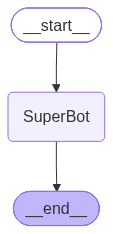

In [42]:
graph = StateGraph(State)

## node
graph.add_node("SuperBot", superbot)

## Edges
graph.add_edge(START, "SuperBot")
graph.add_edge("SuperBot", END)

graph_builder = graph.compile(checkpointer=memory)

## Display
from IPython.display import Image, display

display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [43]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke(
    {"messages": "Hi, My name is Krish And I like cricket"},
    config
)

{'messages': [HumanMessage(content='Hi, My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='b353b637-87e6-4020-81d6-494af385e8c6'),
  AIMessage(content='Hello Krish! 👋 It’s great to meet a cricket fan. Which team or player do you follow the most? Or maybe you have a favorite match or moment you’d like to share?', additional_kwargs={'reasoning_content': 'User says: "Hi, My name is Krish And I like cricket". They are greeting. We should respond politely, maybe ask about cricket. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 84, 'prompt_tokens': 82, 'total_tokens': 166, 'completion_time': 0.085013038, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.003943566, 'prompt_tokens_details': None, 'queue_time': 0.401262691, 'total_time': 0.088956604}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8b41efc9a3', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provid

##### Streaming

**Methods:** `.stream()` and `.astream()`

* These methods are **sync and async methods** for streaming back results.

### Additional parameters in streaming modes for graph state

* **`values`** → Streams the **full state of the graph** after each node is called.
* **`updates`** → Streams the **updates made to the graph state** after each node is called.


In [45]:
# Create a thread
config = {"configurable": {"thread_id": "2"}}

for chunk in graph_builder.stream(
    {"messages": "Hi, My name is dilshad And I like cricket"},
    config,
    stream_mode="updates"
):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Dilshad! 👋 It’s awesome to meet another cricket enthusiast. Which team or player do you follow the most? Or maybe you have a favorite match or moment you’d love to talk about?', additional_kwargs={'reasoning_content': 'User says "Hi, My name is dilshad And I like cricket". They want a response. We should greet them, ask about cricket. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 86, 'prompt_tokens': 144, 'total_tokens': 230, 'completion_time': 0.095975515, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.00804313, 'prompt_tokens_details': None, 'queue_time': 0.04582948, 'total_time': 0.104018645}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e99e93f2ac', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0b828-5a1d-7e53-a019-45e9c61bee3d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_to

In [46]:
for chunk in graph_builder.stream(
    {"messages": "Hi, My name is dilshad And I like cricket"},
    config,
    stream_mode="values"
):
    print(chunk)

{'messages': [HumanMessage(content='Hi, My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='308d7db1-aee3-4c9c-a84b-dd9e0ff259a9'), AIMessage(content='Hello Krish! 👋 It’s great to meet a cricket fan. Which team or player do you follow the most? Or maybe you have a favorite match or moment you’d like to share?', additional_kwargs={'reasoning_content': 'User says: "Hi, My name is Krish And I like cricket". They are greeting. We should respond politely, maybe ask about cricket. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 84, 'prompt_tokens': 82, 'total_tokens': 166, 'completion_time': 0.08868796, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.004001779, 'prompt_tokens_details': None, 'queue_time': 0.34653429, 'total_time': 0.092689739}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_228717f27c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider':

In [47]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream(
    {"messages": "Hi, My name is dilshad And I like cricket"},
    config,
    stream_mode="updates"
):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello Dilshad! 👋 It’s great to meet you. Cricket is such an exciting sport—do you have a favorite team or player? Or maybe you enjoy a particular format like Test, ODI, or T20? Let me know what you’re most into, and we can chat about recent matches, stats, or anything else cricket‑related!', additional_kwargs={'reasoning_content': 'User says: "Hi, My name is dilshad And I like cricket". They are greeting. We should respond politely, ask about cricket. Also mention we are ChatGPT. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 123, 'prompt_tokens': 83, 'total_tokens': 206, 'completion_time': 0.134305472, 'completion_tokens_details': {'reasoning_tokens': 42}, 'prompt_time': 0.005437667, 'prompt_tokens_details': None, 'queue_time': 0.34862851, 'total_time': 0.139743139}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_92d51d08e5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None

In [48]:
for chunk in graph_builder.stream(
    {"messages": "I also like football"},
    config,
    stream_mode="updates"
):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='That’s awesome—so you’re a double‑sport fan! 🎉\n\n- **Cricket**: Do you follow any particular league or national team? Maybe you’re into the IPL, Big Bash, or the international calendar (Tests, ODIs, T20s)?\n- **Football**: Which leagues or clubs do you root for? Premier League, La Liga, Serie A, or maybe you’re a fan of the World Cup or Champions League?\n\nLet me know your favorites or any recent matches that got you excited, and we can dive into stats, player highlights, or even some fun trivia!', additional_kwargs={'reasoning_content': 'User says they like football too. We should respond friendly, ask about favorite teams, etc. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 156, 'prompt_tokens': 169, 'total_tokens': 325, 'completion_time': 0.169958546, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.011570079, 'prompt_tokens_details': None, 'queue_time': 0.310102691, 'total_time': 0.

In [ ]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream(
    {"messages": "Hi, My name is dilshad And I like cricket"},
    config,
    stream_mode="updates"
):
    print(chunk)

In [49]:
config = {"configurable": {"thread_id": "1"}}

async for event in graph_builder.astream_events(
    {"messages": ["Hi My name is Krish and I like to play cricket"]},
    config,
    version="v2"
):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a0b843-fc17-7050-9139-b187edd7928f', 'metadata': {'thread_id': '1', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi, My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='b353b637-87e6-4020-81d6-494af385e8c6'), AIMessage(content='Hello Krish! 👋 It’s great to meet a cricket fan. Which team or player do you follow the most? Or maybe you have a favorite match or moment you’d like to share?', additional_kwargs={'reasoning_content': 'User says: "Hi, My name is Krish And I like cricket". They are greeting. We should respond politely, maybe ask about cricket. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 84, 'prompt_tokens': 82, 'total_tokens': 166, 'completion_time': 0.085013038, 'complet